# Component B: Data quality and profiling

**Student B: Phaneendra.** Profiles `data/raw/immo_data.csv` across five quality dimensions (completeness,
uniqueness, consistency, validity, timeliness), produces three charts and an issue table with likely causes,
downstream impact and suggested cleaning. Outputs go to `outputs/profiling/`.


In [1]:
from pathlib import Path
import pandas as pd

# Search the notebook's working directory and its parents for the project CSV.
relative_csv = Path("data/raw/immo_data.csv")
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / relative_csv).is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        f"Could not find {relative_csv} from {Path.cwd()}. "
        "Run this notebook from the project folder or one of its subfolders."
    )
RAW = ROOT / relative_csv
OUT = ROOT / "outputs" / "profiling"
OUT.mkdir(parents=True, exist_ok=True)
print(RAW.exists(), OUT)

True c:\Users\bspha\OneDrive\Documents\GitHub\german-rent-data-quality\outputs\profiling


## Step 1: Load and look

Read the CSV with pandas (`low_memory=False`). Print shape and the count of each dtype.

In [2]:
df = pd.read_csv(RAW, low_memory=False)
print(df.shape)
print(df.dtypes.value_counts())

(268850, 49)
str        19
float64    18
bool        6
int64       6
Name: count, dtype: int64


## Step 2: Completeness

Missing count and percentage per column, sorted. Save as `missing_profile.csv` in OUT.

In [3]:
missing = df.isna().sum()
pct = (missing / len(df) * 100).round(2)

missing_profile = pd.DataFrame({"missing": missing, "pct": pct})
missing_profile = missing_profile.sort_values("pct", ascending=False)

missing_profile.to_csv(OUT / "missing_profile.csv")
missing_profile.head(15)

,missing,pct
telekomHybridUploadSpeed,223830,83.25
electricityBasePrice,222004,82.58
electricityKwhPrice,222004,82.58
energyEfficiencyClass,191063,71.07
lastRefurbish,188139,69.98
heatingCosts,183332,68.19
noParkSpaces,175798,65.39
petsAllowed,114573,42.62
interiorQual,112665,41.91
thermalChar,106506,39.62


In [4]:
cols = ["electricityBasePrice", "telekomHybridUploadSpeed", "energyEfficiencyClass"]
df[cols].isna().groupby(df["date"]).mean().round(3) * 100

,electricityBasePrice,telekomHybridUploadSpeed,energyEfficiencyClass
date,,,
Feb20,100.0,87.4,67.9
May19,100.0,81.0,71.8
Oct19,100.0,84.1,69.0
Sep18,0.0,78.8,78.2


## Step 3: Hidden missingness

Find placeholder text that `isna()` cannot see, for example `no_information` in `street`. Count it.


In [5]:
print((df["street"] == "no_information").sum())
print(((df["street"] == "no_information") & df["streetPlain"].isna()).sum())

71013
71013


## Step 4: Uniqueness: exact

Count exact duplicate rows and duplicate `scoutId` values.

In [6]:
print("exact duplicate rows:", df.duplicated().sum())
print("duplicate scoutId:", df["scoutId"].duplicated().sum())

exact duplicate rows: 0
duplicate scoutId: 0


## Step 5: Uniqueness: repeat listings


In [7]:
flat_key = ["geo_plz", "street", "baseRent", "livingSpace", "noRooms", "floor"]

repeats = df.duplicated(subset=flat_key)
print("repeat listings:", repeats.sum())

# how many of those groups appear in more than one snapshot?
groups = df[df.duplicated(subset=flat_key, keep=False)]
print("groups across snapshots:", (groups.groupby(flat_key)["date"].nunique() > 1).sum())

repeat listings: 11270
groups across snapshots: 4828


## Step 6: Format consistency

Postcodes: convert `geo_plz` to text and count values shorter than 5 digits.

In [8]:
plz_text = df["geo_plz"].astype(str)
print("postcodes shorter than 5 digits:", (plz_text.str.len() < 5).sum())
plz_text[plz_text.str.len() < 5].head()

postcodes shorter than 5 digits: 75356


2     1097
3     9599
6     9599
10    9130
11    9669
Name: geo_plz, dtype: str

## Step 7: Encoding consistency

Count street names that contain HTML codes such as `&szlig;`.


In [9]:
has_code = df["street"].str.contains("&[a-z]+;", regex=True, na=False)
print("streets with HTML codes:", has_code.sum())
df.loc[has_code, "street"].head()

streets with HTML codes: 104441


0      Sch&uuml;ruferstra&szlig;e
3     Gl&uuml;ck-Auf-Stra&szlig;e
9                 H&uuml;ttenstr.
10             Hofer Stra&szlig;e
18           Kalthoffstra&szlig;e
Name: street, dtype: str

## Step 8: Validity

Nonpositive rent, living space and rooms; construction years in the future or implausibly old. Write down your thresholds.

In [10]:
MIN_YEAR = 1500   # your choice: oldest believable building
MAX_YEAR = 2020   # your choice: last snapshot is Feb 2020

print("baseRent <= 0:", (df["baseRent"] <= 0).sum())
print("livingSpace <= 0:", (df["livingSpace"] <= 0).sum())
print("noRooms <= 0:", (df["noRooms"] <= 0).sum())
print("year before MIN:", (df["yearConstructed"] < MIN_YEAR).sum())
print("year after MAX:", (df["yearConstructed"] > MAX_YEAR).sum())
df[["baseRent", "totalRent", "livingSpace", "noRooms", "yearConstructed"]].describe().round(1)

baseRent <= 0: 89
livingSpace <= 0: 75
noRooms <= 0: 0
year before MIN: 148
year after MAX: 22


,baseRent,totalRent,livingSpace,noRooms,yearConstructed
count,268850.0,228333.0,268850.0,268850.0,211805.0
mean,694.1,901.3,74.4,2.6,1966.4
std,19536.0,33238.3,254.8,2.6,47.0
min,0.0,0.0,0.0,1.0,1000.0
25%,338.0,469.8,54.0,2.0,1950.0
50%,490.0,650.0,67.3,3.0,1973.0
75%,799.0,985.0,87.0,3.0,1996.0
max,9999999.0,15751535.0,111111.0,1000.0,2090.0


## Step 9: Cross-field rules

Rows where floor > numberOfFloors, and where totalRent < baseRent.


In [11]:
print("floor above building height:", (df["floor"] > df["numberOfFloors"]).sum())
print("totalRent below baseRent:", (df["totalRent"] < df["baseRent"]).sum())

floor above building height: 1411
totalRent below baseRent: 444


## Step 10: Timeliness

Rows per snapshot (`date`). How old is the newest snapshot today?

In [12]:
print(df["date"].value_counts())
print("newest snapshot: Feb 2020, about", 2026 - 2020, "years old")

date
Feb20    79276
May19    76047
Oct19    66685
Sep18    46842
Name: count, dtype: int64
newest snapshot: Feb 2020, about 6 years old


## Step 11: Chart 1: completeness

Bar chart of the top 15 columns by missing percentage.

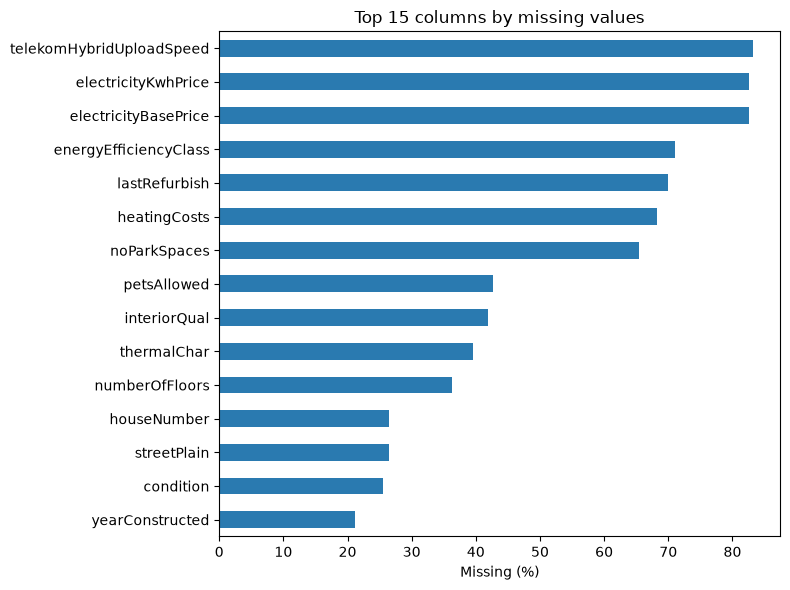

In [13]:
import matplotlib.pyplot as plt

missing_profile["pct"].head(15).sort_values().plot(kind="barh", figsize=(8, 6), color="#2a7ab0")
plt.title("Top 15 columns by missing values")
plt.xlabel("Missing (%)")
plt.tight_layout()
plt.savefig(OUT / "chart1_missing.png", dpi=200)
plt.show()

## Step 12: Chart 2: distribution

Histogram of rent per m2 (baseRent / livingSpace). Drop infinite values, log scale on x.

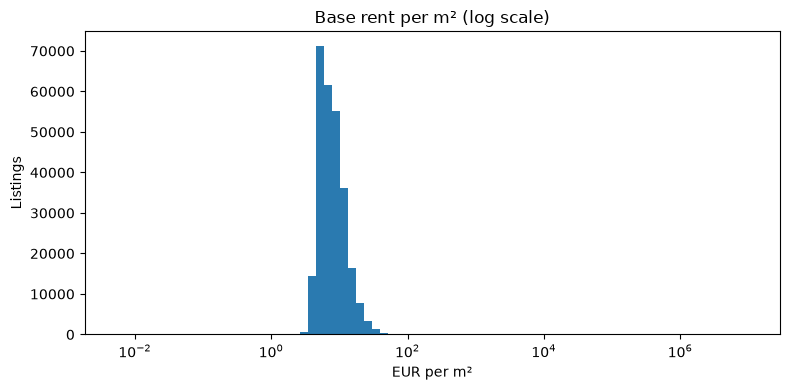

count     268697.00
mean          46.44
std        19292.59
min            0.01
1%             3.94
50%            7.37
99%           28.00
max      9999999.00
dtype: float64


In [14]:
import numpy as np

per_m2 = (df["baseRent"] / df["livingSpace"]).replace([np.inf, -np.inf], np.nan).dropna()
per_m2 = per_m2[per_m2 > 0]

plt.figure(figsize=(8, 4))
plt.hist(per_m2, bins=np.logspace(np.log10(per_m2.min()), np.log10(per_m2.max()), 80), color="#2a7ab0")
plt.xscale("log")
plt.title("Base rent per m² (log scale)")
plt.xlabel("EUR per m²")
plt.ylabel("Listings")
plt.tight_layout()
plt.savefig(OUT / "chart2_rent_per_m2_log.png", dpi=200)
plt.show()
print(per_m2.describe(percentiles=[0.01, 0.5, 0.99]).round(2))

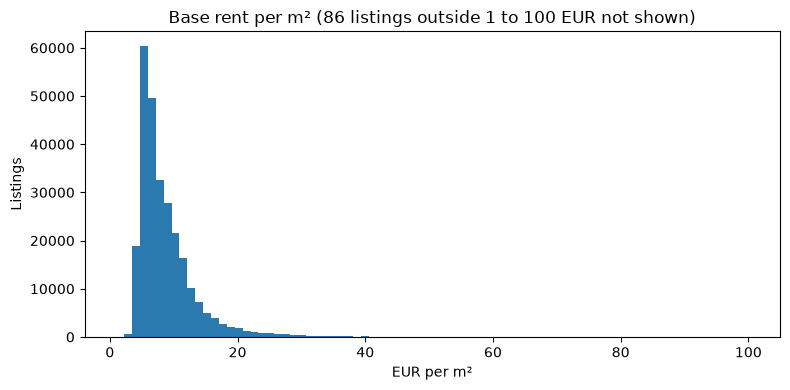

count     268697.00
mean          46.44
std        19292.59
min            0.01
1%             3.94
50%            7.37
99%           28.00
max      9999999.00
dtype: float64


In [15]:
low, high = 1, 100   # believable EUR per m²
outside = ((per_m2 < low) | (per_m2 > high)).sum()

plt.figure(figsize=(8, 4))
plt.hist(per_m2[(per_m2 >= low) & (per_m2 <= high)], bins=80, color="#2a7ab0")
plt.title(f"Base rent per m² ({outside} listings outside {low} to {high} EUR not shown)")
plt.xlabel("EUR per m²")
plt.ylabel("Listings")
plt.tight_layout()
plt.savefig(OUT / "chart2_rent_per_m2.png", dpi=200)
plt.show()
print(per_m2.describe(percentiles=[0.01, 0.5, 0.99]).round(2))

## Step 13: Issue table

Build the issue table from the profiling checks, add notes, and save it before plotting.
Percentages use all rows in the CSV as the denominator. Repeat listings count rows after the first occurrence of each matching key. The rent-per-m² range check uses positive, finite ratios, as in Step 12.


In [16]:
issue_counts = [
    ("Completeness", "Electricity price only collected in Sep18", missing["electricityBasePrice"]),
    ("Completeness", "Placeholder 'no_information' for street", df["street"].eq("no_information").sum()),
    ("Completeness", "Total rent missing", missing["totalRent"]),
    ("Uniqueness", "Same flat listed more than once", repeats.sum()),
    ("Consistency", "Postcode lost its leading zero", (plz_text.str.len() < 5).sum()),
    ("Consistency", "HTML codes in street names", has_code.sum()),
    ("Validity", "Living space zero or negative", df["livingSpace"].le(0).sum()),
    ("Validity", "Construction year impossible",
     (df["yearConstructed"].lt(MIN_YEAR) | df["yearConstructed"].gt(MAX_YEAR)).sum()),
    ("Consistency (cross-field)", "Floor above building height", (df["floor"] > df["numberOfFloors"]).sum()),
    ("Consistency (cross-field)", "Total rent below base rent", (df["totalRent"] < df["baseRent"]).sum()),
    ("Validity", "Rent per m2 outside believable range", outside),
    ("Timeliness", "Newest data is from Feb 2020", len(df)),
]
issues = pd.DataFrame(issue_counts, columns=["dimension", "issue", "affected_rows"])
issues["pct"] = (issues["affected_rows"] / len(df) * 100).round(2)

notes = {
    0:  ["Field only collected in the Sep18 snapshot", "Models can only learn from Sep18 listings", "Drop the column, too sparse to fill"],
    1:  ["Site writes text instead of leaving street empty", "isna() misses it; fake street in groupings", "Replace 'no_information' with a real missing value"],
    2:  ["Optional field, many sellers only give base rent", "Total cost comparisons lose 15% of listings", "Keep missing; do not fill from base rent"],
    3:  ["Same flat re-posted in later snapshots or by two agents", "Repeated flats over-weight their district median", "Keep one copy per flat, the newest snapshot"],
    4:  ["Postcode read as a number, leading zero dropped", "Eastern postcodes fail to match maps or other data", "Read geo_plz as text and pad to 5 digits"],
    5:  ["Scraper saved HTML codes instead of real letters", "Same street appears under two spellings", "Decode HTML codes with Python's html module"],
    6:  ["Form default or typing error", "Rent per m2 becomes infinite or meaningless", "Set to missing and flag, keep the listing"],
    7:  ["Typing errors or placeholder years", "Building age analysis gets distorted", "Set years outside 1500 to 2020 to missing"],
    8:  ["Typo, or ground floor counted differently", "Floor-based features become unreliable", "Flag only; definition is ambiguous"],
    9:  ["Fields swapped or utilities entered as negative", "Total cost per m2 is understated", "Flag and exclude from total rent analysis"],
    10: ["Placeholder values like 9,999,999 or tiny areas", "Means explode; medians mostly survive", "Flag outside 1 to 100 EUR per m2, use medians"],
    11: ["Data scraped 2018 to 2020, before COVID and inflation", "Rents too low for today's market", "Label results as 2018 to 2020; do not use as current rents"],
}
for i, (cause, impact, cleaning) in notes.items():
    issues.loc[i, ["likely_cause", "impact", "suggested_cleaning"]] = [cause, impact, cleaning]

issues.to_csv(OUT / "quality_issues.csv", index=False)
issues

,dimension,issue,affected_rows,pct,likely_cause,impact,suggested_cleaning
0,Completeness,Electricity price only collected in Sep18,222004,82.58,Field only collected in the Sep18 snapshot,Models can only learn from Sep18 listings,"Drop the column, too sparse to fill"
1,Completeness,Placeholder 'no_information' for street,71013,26.41,Site writes text instead of leaving street empty,isna() misses it; fake street in groupings,Replace 'no_information' with a real missing v...
2,Completeness,Total rent missing,40517,15.07,"Optional field, many sellers only give base rent",Total cost comparisons lose 15% of listings,Keep missing; do not fill from base rent
3,Uniqueness,Same flat listed more than once,11270,4.19,Same flat re-posted in later snapshots or by t...,Repeated flats over-weight their district median,"Keep one copy per flat, the newest snapshot"
4,Consistency,Postcode lost its leading zero,75356,28.03,"Postcode read as a number, leading zero dropped",Eastern postcodes fail to match maps or other ...,Read geo_plz as text and pad to 5 digits
5,Consistency,HTML codes in street names,104441,38.85,Scraper saved HTML codes instead of real letters,Same street appears under two spellings,Decode HTML codes with Python's html module
6,Validity,Living space zero or negative,75,0.03,Form default or typing error,Rent per m2 becomes infinite or meaningless,"Set to missing and flag, keep the listing"
7,Validity,Construction year impossible,170,0.06,Typing errors or placeholder years,Building age analysis gets distorted,Set years outside 1500 to 2020 to missing
8,Consistency (cross-field),Floor above building height,1411,0.52,"Typo, or ground floor counted differently",Floor-based features become unreliable,Flag only; definition is ambiguous
9,Consistency (cross-field),Total rent below base rent,444,0.17,Fields swapped or utilities entered as negative,Total cost per m2 is understated,Flag and exclude from total rent analysis


## Step 14: Chart 3: issues by dimension

Plot percentages and affected-row counts from the issue table. Both views omit timeliness because it applies to the entire historical dataset.


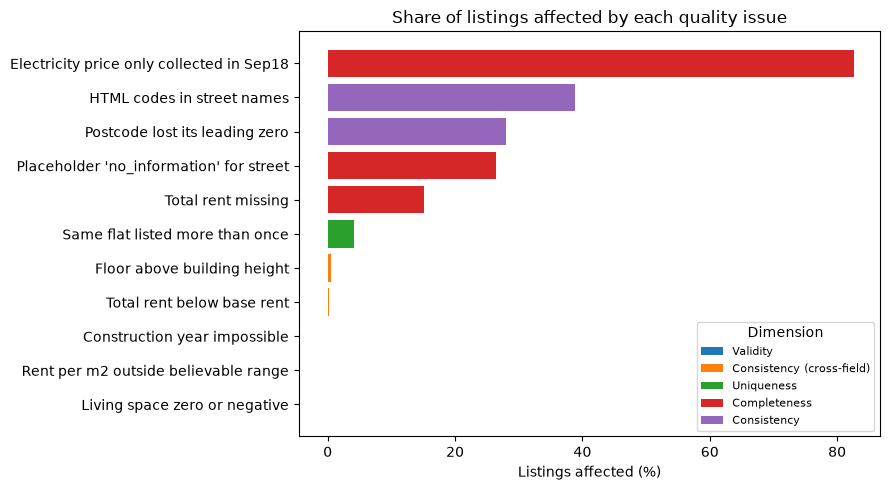

In [17]:
plot_df = issues[issues["dimension"] != "Timeliness"].sort_values("pct")
dims = plot_df["dimension"].unique()
colors = dict(zip(dims, plt.cm.tab10.colors))

plt.figure(figsize=(9, 5))
plt.barh(plot_df["issue"], plot_df["pct"], color=plot_df["dimension"].map(colors))
for d, c in colors.items():
    plt.bar(0, 0, color=c, label=d)
plt.legend(title="Dimension", fontsize=8)
plt.title("Share of listings affected by each quality issue")
plt.xlabel("Listings affected (%)")
plt.tight_layout()
plt.savefig(OUT / "chart3_issues_pct.png", dpi=200)
plt.show()

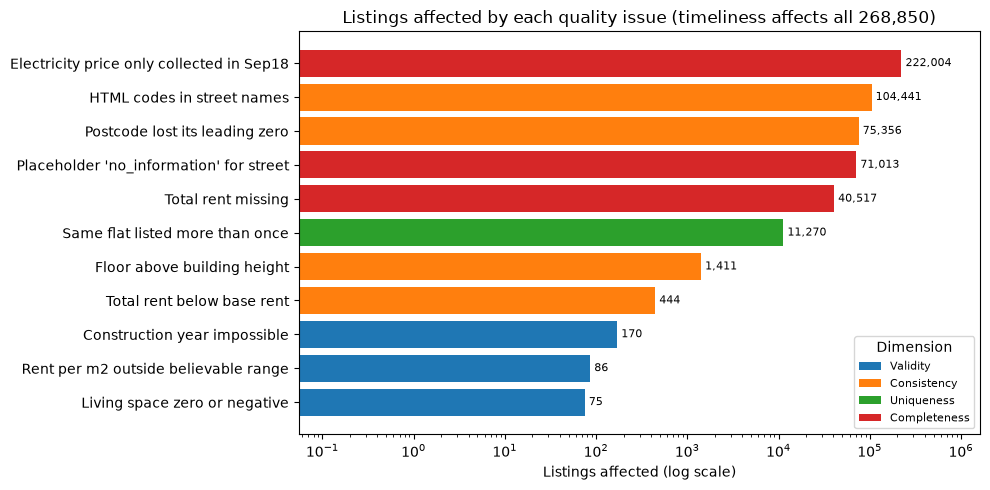

In [18]:
plot_df = issues[issues["dimension"] != "Timeliness"].sort_values("affected_rows").copy()
plot_df["main_dim"] = plot_df["dimension"].str.split(" ").str[0]
colors = dict(zip(plot_df["main_dim"].unique(), plt.cm.tab10.colors))

plt.figure(figsize=(10, 5))
bars = plt.barh(plot_df["issue"], plot_df["affected_rows"], color=plot_df["main_dim"].map(colors))
plt.bar_label(bars, labels=[f"{v:,}" for v in plot_df["affected_rows"]], padding=3, fontsize=8)
count_scale = "symlog" if plot_df["affected_rows"].eq(0).any() else "log"
plt.xscale(count_scale)
plt.margins(x=0.15)
for d, c in colors.items():
    plt.bar(0, 0, color=c, label=d)
plt.legend(title="Dimension", loc="lower right", fontsize=8)
plt.title(f"Listings affected by each quality issue (timeliness affects all {len(df):,})")
plt.xlabel(f"Listings affected ({count_scale} scale)")
plt.tight_layout()
plt.savefig(OUT / "chart3_issues.png", dpi=200)
plt.show()

## Step 15: Issue IDs used by the cleaning pipeline (link to Component C)

Component C cites an issue ID in every audit-log row. This table gives each B issue that ID, so every cleaning
step can be traced back to the problem it fixes. Issues with no cleaning step are kept on purpose (stated in
`c_handling`).

In [19]:
issue_ids = {
    "Electricity price only collected in Sep18": ("C1", "Column dropped (more than 75% missing)"),
    "Placeholder 'no_information' for street": ("C2", "Placeholder turned into a real missing value"),
    "Total rent missing": ("C4", "Kept as missing on purpose; not filled from base rent"),
    "Same flat listed more than once": ("U1", "Near-duplicates removed, newest snapshot kept"),
    "Postcode lost its leading zero": ("F1", "Postcode read as text, leading zero restored"),
    "HTML codes in street names": ("K3", "HTML-coded street column dropped; clean streetPlain kept"),
    "Living space zero or negative": ("V1", "Rows with living space outside 10 to 1,000 m2 removed"),
    "Construction year impossible": ("V2", "Years outside 1500 to 2021 set to missing"),
    "Floor above building height": ("K2", "Flag column floor_above_building added"),
    "Total rent below base rent": ("K1", "Flag column totalRent_consistent added"),
    "Rent per m2 outside believable range": ("V1", "Rows with impossible base rent or living space removed"),
    "Newest data is from Feb 2020": ("T1", "No cleaning possible; results labelled 2018 to 2020"),
}
register = issues.copy()
register.insert(0, "issue_id", register["issue"].map(lambda x: issue_ids.get(x, ("?", ""))[0]))
register["c_handling"] = register["issue"].map(lambda x: issue_ids.get(x, ("?", ""))[1])
print("issues without an ID:", (register["issue_id"] == "?").sum())
register.to_csv(OUT / "issue_register.csv", index=False)
register[["issue_id", "issue", "dimension", "affected_rows", "c_handling"]]

issues without an ID: 0


,issue_id,issue,dimension,affected_rows,c_handling
0,C1,Electricity price only collected in Sep18,Completeness,222004,Column dropped (more than 75% missing)
1,C2,Placeholder 'no_information' for street,Completeness,71013,Placeholder turned into a real missing value
2,C4,Total rent missing,Completeness,40517,Kept as missing on purpose; not filled from ba...
3,U1,Same flat listed more than once,Uniqueness,11270,"Near-duplicates removed, newest snapshot kept"
4,F1,Postcode lost its leading zero,Consistency,75356,"Postcode read as text, leading zero restored"
5,K3,HTML codes in street names,Consistency,104441,HTML-coded street column dropped; clean street...
6,V1,Living space zero or negative,Validity,75,"Rows with living space outside 10 to 1,000 m2 ..."
7,V2,Construction year impossible,Validity,170,Years outside 1500 to 2021 set to missing
8,K2,Floor above building height,Consistency (cross-field),1411,Flag column floor_above_building added
9,K1,Total rent below base rent,Consistency (cross-field),444,Flag column totalRent_consistent added
